**ESOPHAGEAL CANCER CLASSIFICATION USING LOGISTIC REGRESSION FOR SAVE IMAGES**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression  # Import Logistic Regression
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import tensorflow as tf

In [ ]:
# Constants
BATCH_SIZE = 32
IMAGE_SIZE = 640
CHANNELS = 3

In [ ]:
import tensorflow as tf
import numpy as np

# Define the paths
train_dir = '/content/drive/MyDrive/new_dataset_EC/Classification/Classification/SAVE_split/train'
val_dir = '/content/drive/MyDrive/new_dataset_EC/Classification/Classification/SAVE_split/val'
test_dir = '/content/drive/MyDrive/new_dataset_EC/Classification/Classification/SAVE_split/test'

# Function to load and flatten the dataset
def load_and_flatten_data(directory, image_size=(224, 224), batch_size=32):
    # Load images from the directory
    dataset = tf.keras.preprocessing.image_dataset_from_directory(
        directory,
        image_size=image_size,
        batch_size=batch_size,
        shuffle=True
    )

    # Flatten the images and extract labels
    flat_data = []
    target_data = []
    for image_batch, labels_batch in dataset:
        for img, label in zip(image_batch, labels_batch):
            img_array = img.numpy().astype('uint8')  # Convert image to NumPy array
            img_flattened = img_array.flatten()      # Flatten the image
            flat_data.append(img_flattened)          # Append flattened image to the list
            target_data.append(label.numpy())        # Append label to the list

    return np.array(flat_data), np.array(target_data)

# Load and flatten each dataset
train_flat_data, train_labels = load_and_flatten_data(train_dir)
val_flat_data, val_labels = load_and_flatten_data(val_dir)
test_flat_data, test_labels = load_and_flatten_data(test_dir)

# Now you can use these flattened datasets for logistic regression


Found 751 files belonging to 3 classes.
Found 214 files belonging to 3 classes.
Found 109 files belonging to 3 classes.


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Assign the flattened data to X and y variables for clarity
X_train, y_train = train_flat_data, train_labels
X_val, y_val = val_flat_data, val_labels
X_test, y_test = test_flat_data, test_labels

# Initialize the Logistic Regression model
logistic_model = LogisticRegression(max_iter=1000)  # Increase max_iter if convergence issues arise

# Train the model on the training data
logistic_model.fit(X_train, y_train)

# Evaluate the model on the validation data
y_val_pred = logistic_model.predict(X_val)
val_accuracy = accuracy_score(y_val, y_val_pred)
print(f'Validation Accuracy: {val_accuracy:.2f}')

# Evaluate the model on the test data
y_test_pred = logistic_model.predict(X_test)
test_accuracy = accuracy_score(y_test, y_test_pred)
print(f'Test Accuracy: {test_accuracy:.2f}')

# Generate a classification report
print("\nClassification Report on Test Data:")
print(classification_report(y_test, y_test_pred))

# Generate a confusion matrix
print("\nConfusion Matrix on Test Data:")
print(confusion_matrix(y_test, y_test_pred))


Validation Accuracy: 0.66
Test Accuracy: 0.75

Classification Report on Test Data:
              precision    recall  f1-score   support

           0       0.77      0.80      0.79        41
           1       0.72      0.82      0.77        34
           2       0.78      0.62      0.69        34

    accuracy                           0.75       109
   macro avg       0.75      0.75      0.75       109
weighted avg       0.76      0.75      0.75       109


Confusion Matrix on Test Data:
[[33  3  5]
 [ 5 28  1]
 [ 5  8 21]]


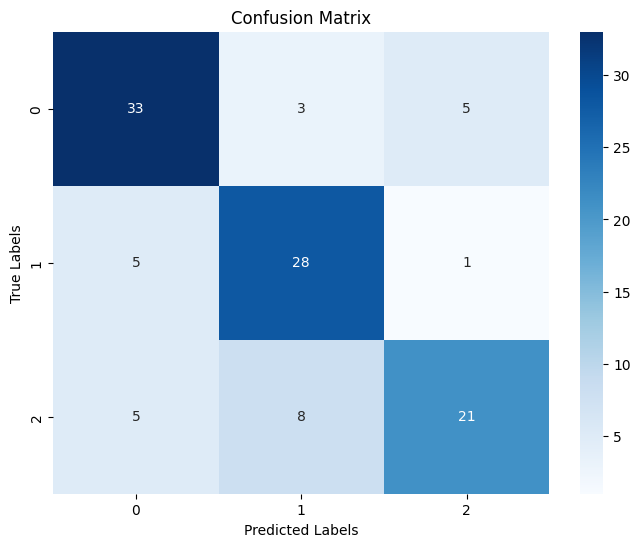

In [ ]:
# Assuming 'y_test' and 'y_test_pred' are defined from the previous code
cm = confusion_matrix(y_test, y_test_pred)

# Plot the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()


In [ ]:
class_names = os.listdir(train_dir)
for index, class_name in enumerate(class_names):
  print(f"Class index: {index}, Class name: {class_name}")


Class index: 0, Class name: Dysplasia
Class index: 1, Class name: Normal
Class index: 2, Class name: SCC


In [ ]:
# Assuming 'train_dir' is the directory containing subdirectories for each class
class_names = os.listdir(train_dir)

for index, class_name in enumerate(class_names):
  print(f"Index: {index}, Class Name: {class_name}")


Index: 0, Class Name: Dysplasia
Index: 1, Class Name: Normal
Index: 2, Class Name: SCC


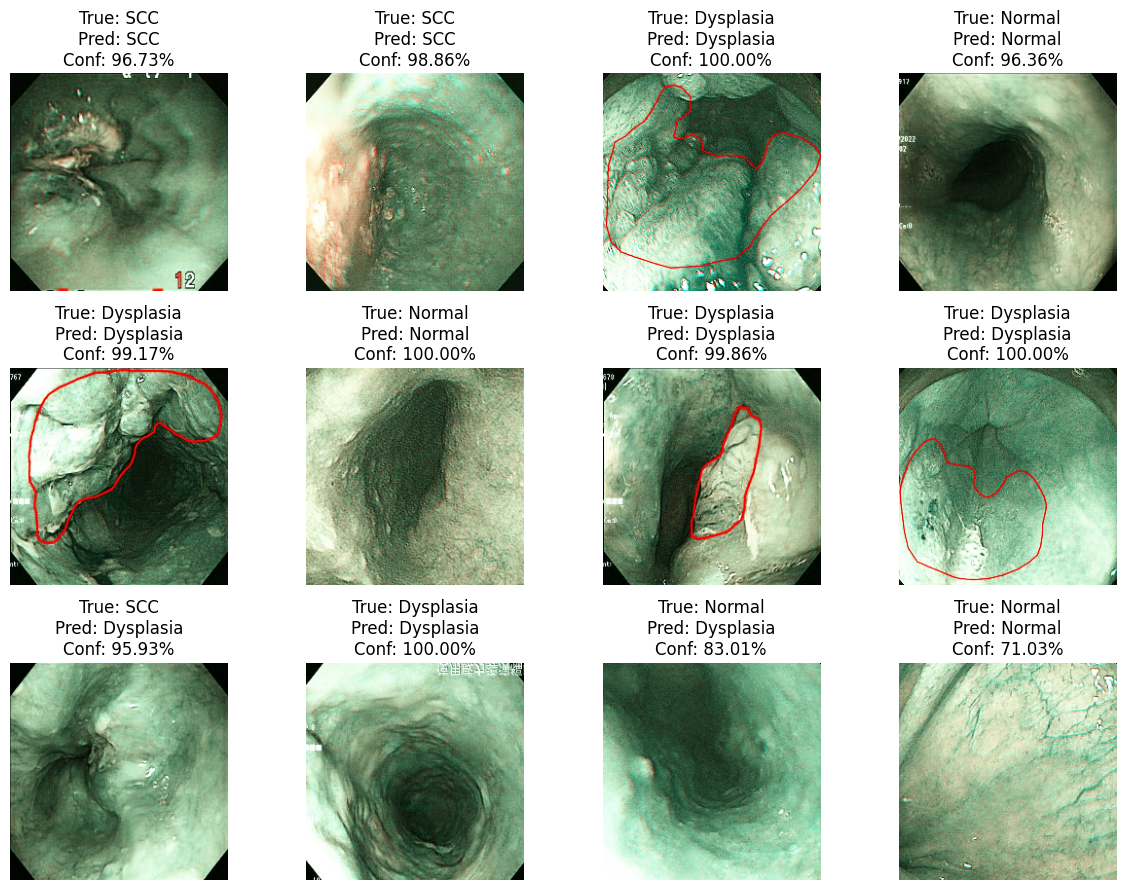

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Assuming you have already loaded your test dataset and logistic model

# Make predictions and get prediction probabilities for the test dataset
y_test_pred = logistic_model.predict(X_test)  # Predicted labels
y_test_prob = logistic_model.predict_proba(X_test)  # Probabilities of each class

# Function to display images with predictions and confidence
def display_predictions(images, true_labels, predicted_labels, probabilities, class_names, num_images=12):
    plt.figure(figsize=(12, 9))  # Set the figure size
    for i in range(num_images):
        plt.subplot(3, 4, i + 1)  # 3x4 grid for displaying 12 images
        img = images[i].reshape(224, 224, 3)  # Reshape flat image back to 3D (adjust according to image size)
        plt.imshow(img)
        true_label = class_names[true_labels[i]]
        predicted_label = class_names[predicted_labels[i]]
        confidence = np.max(probabilities[i]) * 100  # Highest probability as confidence score
        plt.title(f"True: {true_label}\nPred: {predicted_label}\nConf: {confidence:.2f}%")
        plt.axis('off')  # Turn off axis

    plt.tight_layout()
    plt.show()

# Assuming you have your class names available
class_names = ['Dysplasia', 'Normal', 'SCC']  # Replace with your actual class names

# Display 12 predictions
display_predictions(test_flat_data, y_test, y_test_pred, y_test_prob, class_names, num_images=12) # Changed test_images to test_flat_data

In [ ]:
import joblib
# Save the trained Logistic Regression model to your working directory
joblib.dump(logistic_model, '/content/drive/MyDrive/new_dataset_EC/logistic fina/logistic_regression_model_SAVE.pkl')


['/content/drive/MyDrive/new_dataset_EC/logistic fina/logistic_regression_model_SAVE.pkl']

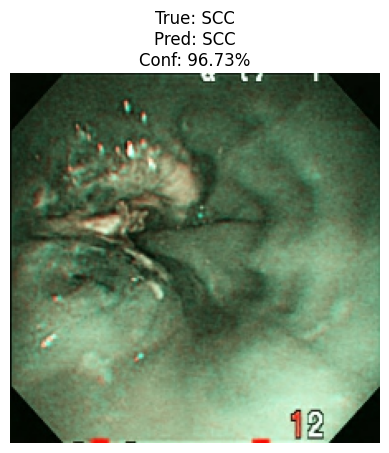

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
# Load the saved model
loaded_logistic_model = joblib.load('/content/drive/MyDrive/new_dataset_EC/logistic fina/logistic_regression_model_SAVE.pkl')

# Choose a single image from the test data
image_index = 0  # You can change this to any index within the range of your test data
single_image = X_test[image_index]

# Make a prediction using the loaded model
prediction = loaded_logistic_model.predict([single_image])
probability = loaded_logistic_model.predict_proba([single_image])

# Get the predicted class and confidence
predicted_class_index = prediction[0]
predicted_class_name = class_names[predicted_class_index]
confidence = np.max(probability[0]) * 100

# Get the true class
true_class_index = y_test[image_index]
true_class_name = class_names[true_class_index]

# Display the image, true class, predicted class, and confidence
img = single_image.reshape(224, 224, 3)  # Reshape the flat image
plt.imshow(img)
plt.title(f"True: {true_class_name}\nPred: {predicted_class_name}\nConf: {confidence:.2f}%")
plt.axis('off')
plt.show()


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

import matplotlib.pyplot as plt
import numpy as np
import joblib
import os
# Assuming you have your class names available
class_names = ['Dysplasia', 'Normal', 'SCC']  # Replace with your actual class names

# Load the saved model
loaded_model = joblib.load('/content/drive/MyDrive/new_dataset_EC/ec/EC/final/logistic_final/logistic_regression_model_SAVE.pkl')

# Get a test image from the SCC folder
test_scc_dir = '/content/drive/MyDrive/new_dataset_EC/Classification/Classification/SAVE_split/test/SCC'

# Loop through all images in the SCC folder
for image_name in os.listdir(test_scc_dir):
    image_path = os.path.join(test_scc_dir, image_name)

    # Check if the file is an image (you can adjust the check as needed)
    if image_name.lower().endswith(('.png', '.jpg', '.jpeg')):
        try:
            img = tf.keras.preprocessing.image.load_img(image_path, target_size=(224, 224))
            img_array = tf.keras.preprocessing.image.img_to_array(img)
            img_array = img_array.astype('uint8')
            img_flattened = img_array.flatten()

            # Reshape the image
            single_image_reshaped = img_flattened.reshape(1, -1)

            # Make a prediction
            predicted_label = loaded_model.predict(single_image_reshaped)[0]
            predicted_prob = loaded_model.predict_proba(single_image_reshaped)[0]

            # Get the predicted class name and confidence
            predicted_class = class_names[predicted_label]
            confidence = np.max(predicted_prob) * 100

            # Display the image with prediction and true label
            plt.figure()
            plt.imshow(img)
            plt.title(f"Image: {image_name}\nTruth: SCC\nPred: {predicted_class}\nConf: {confidence:.2f}%")
            plt.axis('off')
            plt.show()

        except Exception as e:
            print(f"Error processing image '{image_name}': {e}")


Output hidden; open in https://colab.research.google.com to view.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
# Assuming you have your class names available
class_names = ['Dysplasia', 'Normal', 'SCC']  # Replace with your actual class names

# Load the saved model
loaded_model = joblib.load('/content/drive/MyDrive/new_dataset_EC/ec/EC/final/logistic_final/logistic_regression_model_SAVE.pkl')

# Get a test image from the Dysplasia folder
test_dysplasia_dir = '/content/drive/MyDrive/new_dataset_EC/Classification/Classification/SAVE_split/test/Dysplasia'

# Loop through all images in the Dysplasia folder
for image_name in os.listdir(test_dysplasia_dir):
    image_path = os.path.join(test_dysplasia_dir, image_name)

    # Check if the file is an image (you can adjust the check as needed)
    if image_name.lower().endswith(('.png', '.jpg', '.jpeg')):
        try:
            img = tf.keras.preprocessing.image.load_img(image_path, target_size=(224, 224))
            img_array = tf.keras.preprocessing.image.img_to_array(img)
            img_array = img_array.astype('uint8')
            img_flattened = img_array.flatten()

            # Reshape the image
            single_image_reshaped = img_flattened.reshape(1, -1)

            # Make a prediction
            predicted_label = loaded_model.predict(single_image_reshaped)[0]
            predicted_prob = loaded_model.predict_proba(single_image_reshaped)[0]

            # Get the predicted class name and confidence
            predicted_class = class_names[predicted_label]
            confidence = np.max(predicted_prob) * 100

            # Display the image with prediction and true label
            plt.figure()
            plt.imshow(img)
            plt.title(f"Image: {image_name}\nTruth: Dysplasia\nPred: {predicted_class}\nConf: {confidence:.2f}%")
            plt.axis('off')
            plt.show()

        except Exception as e:
            print(f"Error processing image '{image_name}': {e}")


Output hidden; open in https://colab.research.google.com to view.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
# Assuming you have your class names available
class_names = ['Dysplasia', 'Normal', 'SCC']  # Replace with your actual class names

# Load the saved model
loaded_model = joblib.load('/content/drive/MyDrive/new_dataset_EC/ec/EC/final/logistic_final/logistic_regression_model_SAVE.pkl')

# Get a test image from the Normal folder
test_normal_dir = '/content/drive/MyDrive/new_dataset_EC/Classification/Classification/SAVE_split/test/Normal'

# Loop through all images in the Normal folder
for image_name in os.listdir(test_normal_dir):
    image_path = os.path.join(test_normal_dir, image_name)

    # Check if the file is an image (you can adjust the check as needed)
    if image_name.lower().endswith(('.png', '.jpg', '.jpeg')):
        try:
            img = tf.keras.preprocessing.image.load_img(image_path, target_size=(224, 224))
            img_array = tf.keras.preprocessing.image.img_to_array(img)
            img_array = img_array.astype('uint8')
            img_flattened = img_array.flatten()

            # Reshape the image
            single_image_reshaped = img_flattened.reshape(1, -1)

            # Make a prediction
            predicted_label = loaded_model.predict(single_image_reshaped)[0]
            predicted_prob = loaded_model.predict_proba(single_image_reshaped)[0]

            # Get the predicted class name and confidence
            predicted_class = class_names[predicted_label]
            confidence = np.max(predicted_prob) * 100

            # Display the image with prediction and true label
            plt.figure()
            plt.imshow(img)
            plt.title(f"Image: {image_name}\nTruth: Normal\nPred: {predicted_class}\nConf: {confidence:.2f}%")
            plt.axis('off')
            plt.show()

        except Exception as e:
            print(f"Error processing image '{image_name}': {e}")


Output hidden; open in https://colab.research.google.com to view.